# Step 4 - Evaluation and Interpretability

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.sparse as sp
from IPython.display import display

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import interpretability as interp

# Inputs
PROCESSED_H5AD = ROOT / "data/processed/work_processed.h5ad"  # notebook 01
EXPORT_ROOT = ROOT / "data/graph_engineering_50pc"  # notebook 02: PCs, masks, graphs
GNN_ROOT = ROOT / "data/gnn_training_50pc"  # notebook 03
CHECKPOINT_DIRS = {
    "main": GNN_ROOT,
    "scarcity": GNN_ROOT / "scarcity",
    "depth": GNN_ROOT / "depth",
}
# Final model: the original checkpoint with the best validation macro-F1
FINAL_CHECKPOINT = GNN_ROOT / "scarcity/gcn_20pct_knn_depth2_seed123.pt"
MLP_PREDICTIONS = {
    budget: EXPORT_ROOT / f"results/{budget}__mlp_predictions.npy"
    for budget in ["5pct", "full"]
}

# Outputs
OUT = ROOT / "data/interpretability"
OUT.mkdir(parents=True, exist_ok=True)

# The Step 3 grid
SEEDS = [42, 123, 2024]
MODELS = ["gcn", "graphsage", "gat", "gated_gcn"]
ABLATION_MODELS = ["gcn", "gated_gcn"]
BUDGETS = ["1pct", "2pct", "5pct", "10pct", "20pct", "full"]
DEPTHS = [1, 2, 3, 4]

# The configuration interpreted in depth in sections 2-7
FOCUS_BUDGET, FOCUS_GRAPH, FOCUS_DEPTH = "5pct", "knn", 2
FOCUS_MODELS = ["gcn", "gated_gcn", "graphsage"]
UMAP_CELLS = 15000

cache = interp.DataCache(EXPORT_ROOT)  # loads each (budget, graph) export once

## 1. Scores

In [2]:
specs = (
    interp.run_grid("main", MODELS, ["5pct", "full"], ["knn", "snn"], [2], SEEDS)
    + interp.run_grid("scarcity", ABLATION_MODELS, BUDGETS, ["knn"], [2], SEEDS)
    + interp.run_grid("depth", ABLATION_MODELS, ["5pct"], ["knn"], DEPTHS, SEEDS)
)
results, outputs = interp.evaluate_runs(specs, cache, CHECKPOINT_DIRS, "validation")
results.to_csv(OUT / "validation_scores_by_run.csv", index=False)

In [3]:
mlp = interp.load_mlp_baseline(MLP_PREDICTIONS, cache)
summary = interp.seed_summary(results)
summary.to_csv(OUT / "validation_summary.csv", index=False)
print("Validation macro-F1, mean ± sd over seeds (MLP: notebook 02, one seed):")
display(interp.headline_table(summary, mlp, MODELS, BUDGETS))

Validation macro-F1, mean ± sd over seeds (MLP: notebook 02, one seed):


model                                    gcn      graphsage            gat  \
experiment budget graph depth                                                
main       5pct   knn   2      0.369 ± 0.003  0.403 ± 0.003  0.381 ± 0.010   
                  snn   2      0.373 ± 0.002  0.396 ± 0.005  0.144 ± 0.052   
           full   knn   2      0.391 ± 0.008  0.406 ± 0.004  0.394 ± 0.009   
                  snn   2      0.389 ± 0.002  0.397 ± 0.004  0.171 ± 0.025   
scarcity   1pct   knn   2      0.309 ± 0.004                                 
           2pct   knn   2      0.349 ± 0.003                                 
           5pct   knn   2      0.369 ± 0.003                                 
           10pct  knn   2      0.387 ± 0.006                                 
           20pct  knn   2      0.412 ± 0.007                                 
           full   knn   2      0.391 ± 0.008                                 
depth      5pct   knn   1      0.256 ± 0.028                                 
                        2      0.369 ± 0.003                                 
                        3      0.371 ± 0.013                                 
                        4      0.374 ± 0.017                                 

model                              gated_gcn    mlp  
experiment budget graph depth                        
main       5pct   knn   2      0.392 ± 0.007  0.422  
                  snn   2      0.388 ± 0.002  0.422  
           full   knn   2      0.399 ± 0.002  0.422  
                  snn   2      0.397 ± 0.002  0.422  
scarcity   1pct   knn   2      0.319 ± 0.006         
           2pct   knn   2      0.370 ± 0.002         
           5pct   knn   2      0.392 ± 0.007  0.422  
           10pct  knn   2      0.408 ± 0.005         
           20pct  knn   2      0.407 ± 0.007         
           full   knn   2      0.399 ± 0.002  0.422  
depth      5pct   knn   1      0.255 ± 0.019  0.422  
                        2      0.392 ± 0.007  0.422  
                        3      0.409 ± 0.002  0.422  
                        4      0.316 ± 0.130  0.422

In [4]:
paired = pd.concat(
    interp.paired_seed_delta(results, "gated_gcn", other).assign(
        comparison=f"gated_gcn - {other}"
    )
    for other in ["gcn", "graphsage"]
)
paired.to_csv(OUT / "validation_paired_deltas.csv", index=False)
print("Per-seed macro-F1 differences on identical settings:")
display(paired.round(3))

Per-seed macro-F1 differences on identical settings:


,experiment,budget,graph,depth,mean,std,min,max,count,comparison
0,depth,5pct,knn,1,-0.000,0.037,-0.041,0.033,3,gated_gcn - gcn
1,depth,5pct,knn,2,0.023,0.005,0.019,0.028,3,gated_gcn - gcn
2,depth,5pct,knn,3,0.038,0.014,0.023,0.049,3,gated_gcn - gcn
3,depth,5pct,knn,4,-0.059,0.143,-0.222,0.043,3,gated_gcn - gcn
4,main,5pct,knn,2,0.023,0.005,0.019,0.028,3,gated_gcn - gcn
5,main,5pct,snn,2,0.015,0.003,0.012,0.017,3,gated_gcn - gcn
6,main,full,knn,2,0.008,0.006,0.002,0.015,3,gated_gcn - gcn
7,main,full,snn,2,0.008,0.003,0.006,0.012,3,gated_gcn - gcn
8,scarcity,10pct,knn,2,0.021,0.010,0.012,0.033,3,gated_gcn - gcn
9,scarcity,1pct,knn,2,0.009,0.002,0.007,0.011,3,gated_gcn - gcn


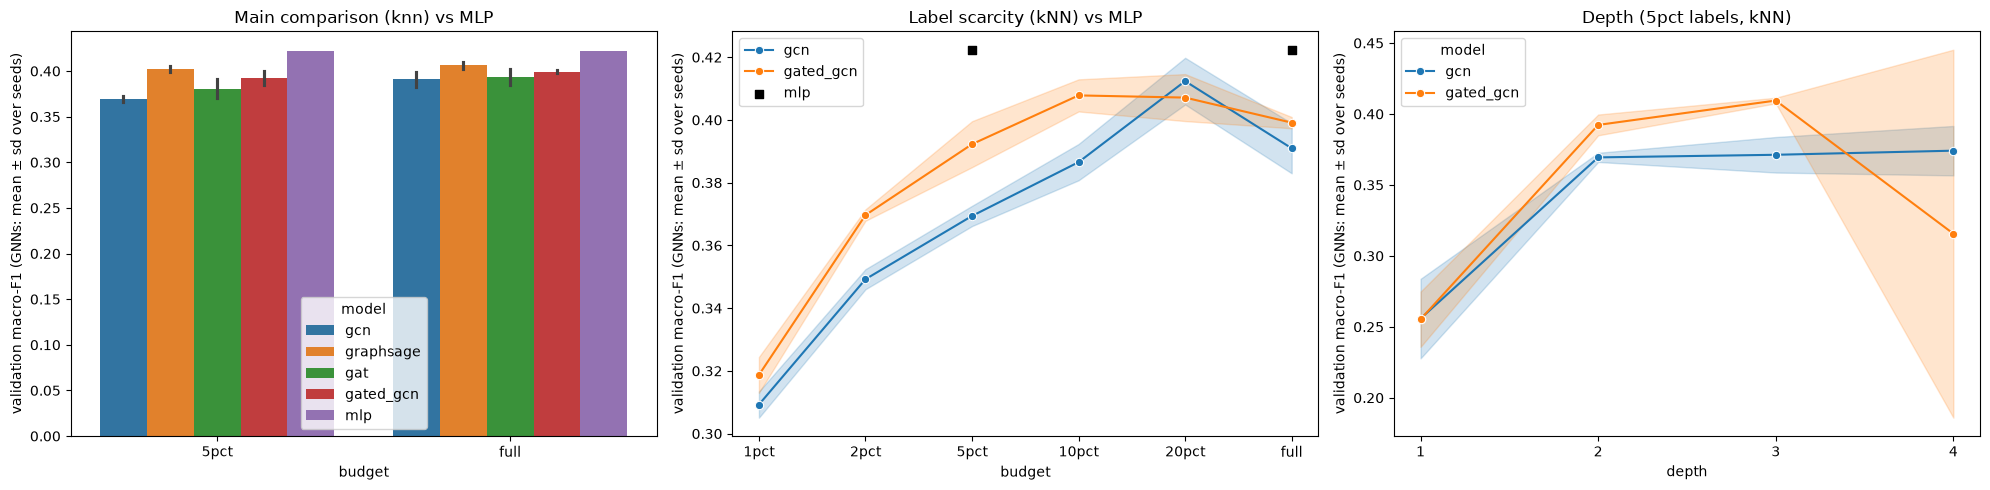

In [5]:
fig = interp.plot_overview(results, mlp, BUDGETS, FOCUS_GRAPH, FOCUS_BUDGET)
fig.savefig(OUT / "validation_overview.png", dpi=150)

In [6]:
final, _ = interp.evaluate_runs(
    [interp.RunSpec.from_checkpoint(FINAL_CHECKPOINT)], cache, CHECKPOINT_DIRS, "test"
)
final.to_csv(OUT / "test_final_model.csv", index=False)
metrics = ["accuracy", "macro_f1", *[c for c in final if c.startswith("f1::")]]
display(final[metrics].T.set_axis(["test"], axis=1).round(3))

,test
accuracy,0.408
macro_f1,0.410
f1::CD14+ Monocyte,0.732
f1::CD19+ B,0.667
f1::CD34+,0.634
f1::CD4+ T Helper2,0.006
f1::CD4+/CD25 T Reg,0.237
f1::CD4+/CD45RA+/CD25- Naive T,0.081
f1::CD4+/CD45RO+ Memory,0.126
f1::CD56+ NK,0.779


## 2. Confusion structure and label granularity

In [7]:
# Sections 2-7 interpret the focus setting (FOCUS_BUDGET, FOCUS_GRAPH,
# FOCUS_DEPTH) for all seeds; labels are for analysis only.
focus_data = cache.get(FOCUS_BUDGET, FOCUS_GRAPH)
class_names = focus_data.class_names
labels = interp.all_labels(focus_data)
cell_types = np.asarray(focus_data.cell_types)
focus_runs = {
    model: {
        seed: outputs[
            interp.RunSpec(model, FOCUS_BUDGET, FOCUS_GRAPH, FOCUS_DEPTH, seed)
        ]
        for seed in SEEDS
    }
    for model in FOCUS_MODELS
}

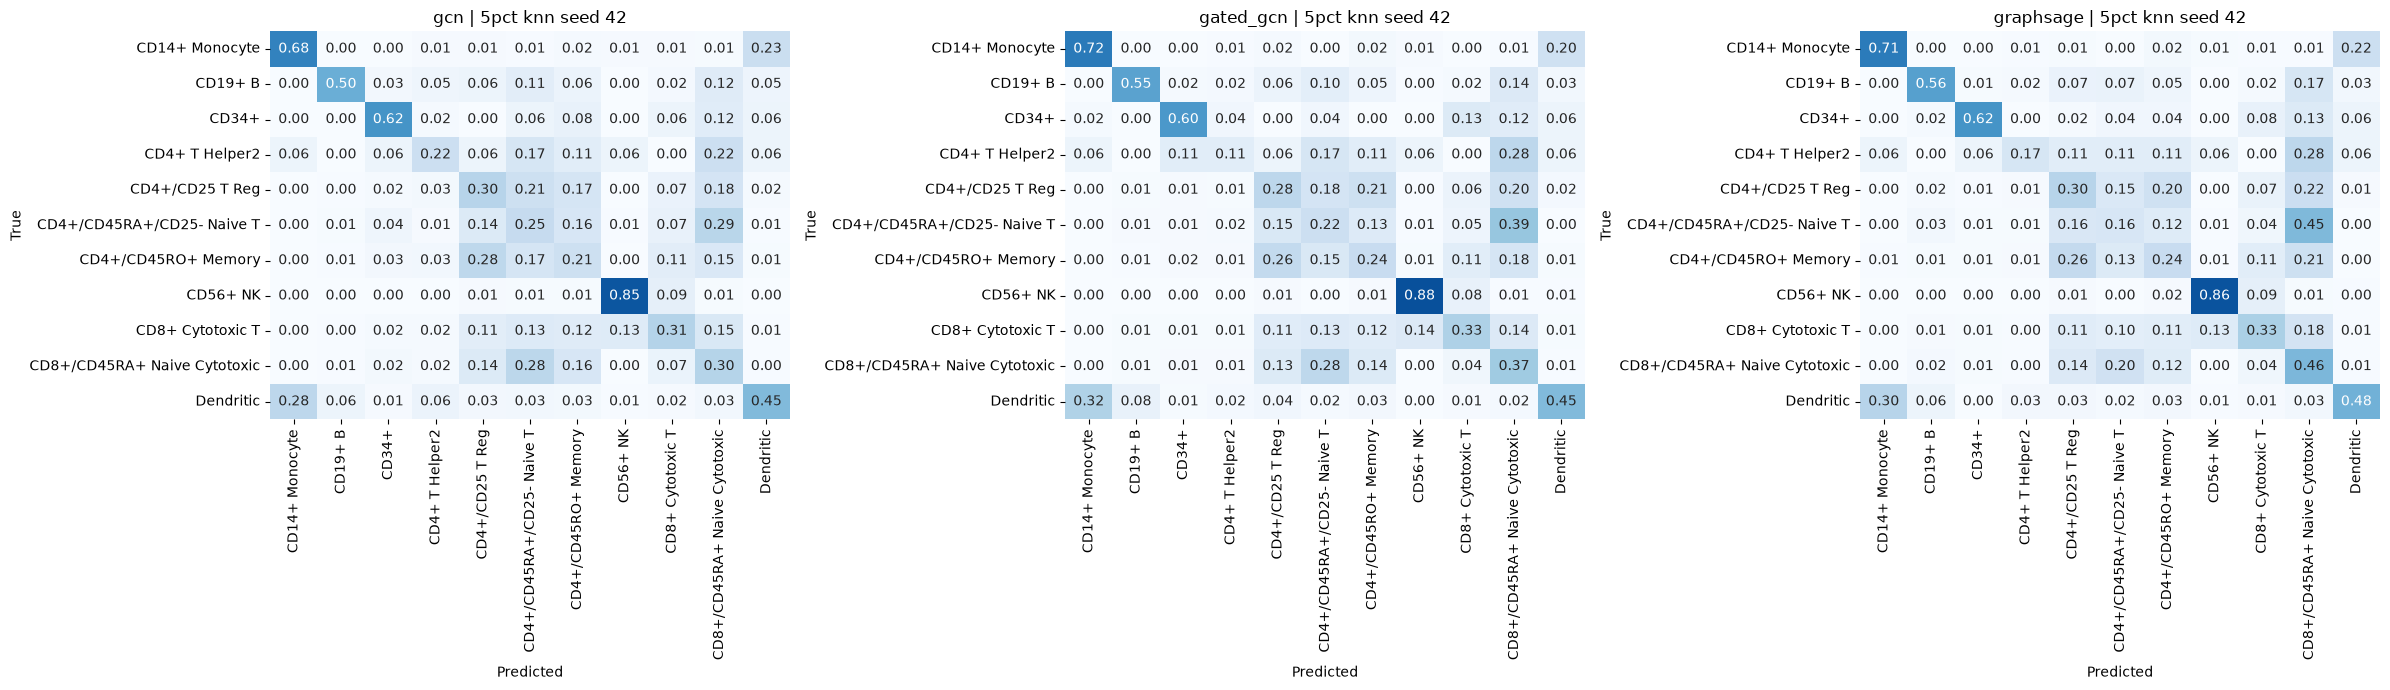

In [8]:
first_seed = {model: runs[SEEDS[0]] for model, runs in focus_runs.items()}
fig = interp.plot_confusions(
    first_seed, class_names, f"{FOCUS_BUDGET} {FOCUS_GRAPH} seed {SEEDS[0]}"
)
fig.savefig(OUT / "validation_confusion.png", dpi=150)

In [9]:
granularity = interp.granularity_table(outputs, cache)
granularity.to_csv(OUT / "validation_granularity.csv")
display(granularity.round(3))

fine_macro_f1  coarse_macro_f1  within_t_error_share
budget graph model                                                          
5pct   knn   gat                0.381            0.631                 0.724
             gated_gcn          0.392            0.644                 0.736
             gcn                0.369            0.616                 0.733
             graphsage          0.403            0.654                 0.727
       snn   gat                0.144            0.295                 0.626
             gated_gcn          0.388            0.637                 0.737
             gcn                0.373            0.623                 0.739
             graphsage          0.396            0.647                 0.728
full   knn   gat                0.394            0.665                 0.754
             gated_gcn          0.399            0.663                 0.759
             gcn                0.391            0.662                 0.762
             graphsage          0.406            0.661                 0.750
       snn   gat                0.171            0.348                 0.603
             gated_gcn          0.397            0.659                 0.756
             gcn                0.389            0.654                 0.760
             graphsage          0.397            0.654                 0.752

## 3. Per-class F1 vs homophily

In [10]:
adjacency = sp.load_npz(EXPORT_ROOT / "graphs" / f"{FOCUS_GRAPH}_adjacency.npz")
local = interp.local_homophily(adjacency, labels)  # per cell; reused in 4 and 6
per_class = interp.per_class_vs_homophily(
    results,
    interp.class_homophily(adjacency, labels, class_names),
    class_names,
    FOCUS_BUDGET,
    FOCUS_GRAPH,
)
per_class.to_csv(OUT / "validation_per_class_vs_homophily.csv")
display(per_class.round(3))
tests = interp.homophily_tests(
    per_class, ["gcn", "gated_gcn", "graphsage", "gate_gain"]
)
display(tests.round(4))

,gat,gated_gcn,gcn,graphsage,cells,endpoint_homophily,mean_local_homophily,gate_gain
CD14+ Monocyte,0.706,0.718,0.718,0.733,2736,0.634,0.616,0.000
CD19+ B,0.643,0.668,0.649,0.635,5601,0.543,0.542,0.019
CD34+,0.343,0.320,0.209,0.390,259,0.594,0.561,0.112
CD4+ T Helper2,0.022,0.033,0.018,0.047,91,0.003,0.003,0.015
CD4+/CD25 T Reg,0.261,0.251,0.260,0.257,5897,0.157,0.162,-0.009
CD4+/CD45RA+/CD25- Naive T,0.078,0.071,0.072,0.072,1800,0.044,0.044,-0.000
CD4+/CD45RO+ Memory,0.118,0.133,0.119,0.135,2931,0.073,0.074,0.013
CD56+ NK,0.784,0.788,0.786,0.793,8423,0.672,0.660,0.002
CD8+ Cytotoxic T,0.422,0.449,0.405,0.460,19892,0.416,0.420,0.044
CD8+/CD45RA+ Naive Cytotoxic,0.405,0.427,0.404,0.448,16007,0.411,0.411,0.023


,quantity,rho,p_permutation,n
0,gcn,0.8364,0.0029,11
1,gated_gcn,0.8818,0.0010,11
2,graphsage,0.9000,0.0008,11
3,gate_gain,0.2273,0.4984,11


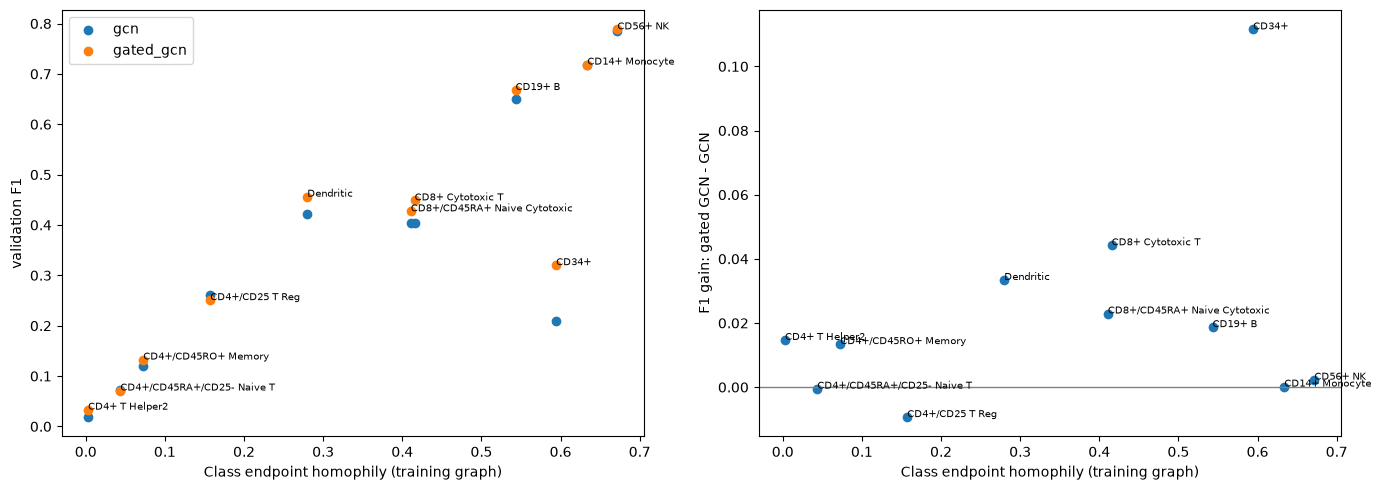

In [11]:
fig = interp.plot_per_class_vs_homophily(per_class)
fig.savefig(OUT / "validation_per_class_vs_homophily.png", dpi=150)

## 4. Gate vs homophily

In [12]:
gate_summary, within_class, class_means = interp.gate_vs_homophily(
    focus_runs["gated_gcn"], local, cell_types, class_names
)
gate_summary.to_csv(OUT / "validation_gate_vs_homophily.csv", index=False)
within_class.to_csv(OUT / "validation_gate_within_class.csv")
display(gate_summary.round(4))
display(within_class.round(3))

,seed,overall_rho,class_level_rho,class_level_p,median_within_class_rho
0,42,-0.0578,-0.0182,0.9680,0.1048
1,123,-0.0180,-0.0636,0.8650,0.1046
2,2024,-0.0436,-0.3364,0.3193,-0.0308


,rho,n
celltype,,
CD14+ Monocyte,-0.061,547.0
CD19+ B,0.781,1121.0
CD34+,0.434,52.0
CD4+ T Helper2,NaN,18.0
CD4+/CD25 T Reg,0.108,1180.0
CD4+/CD45RA+/CD25- Naive T,-0.112,360.0
CD4+/CD45RO+ Memory,0.119,586.0
CD56+ NK,-0.131,1684.0
CD8+ Cytotoxic T,-0.063,3978.0


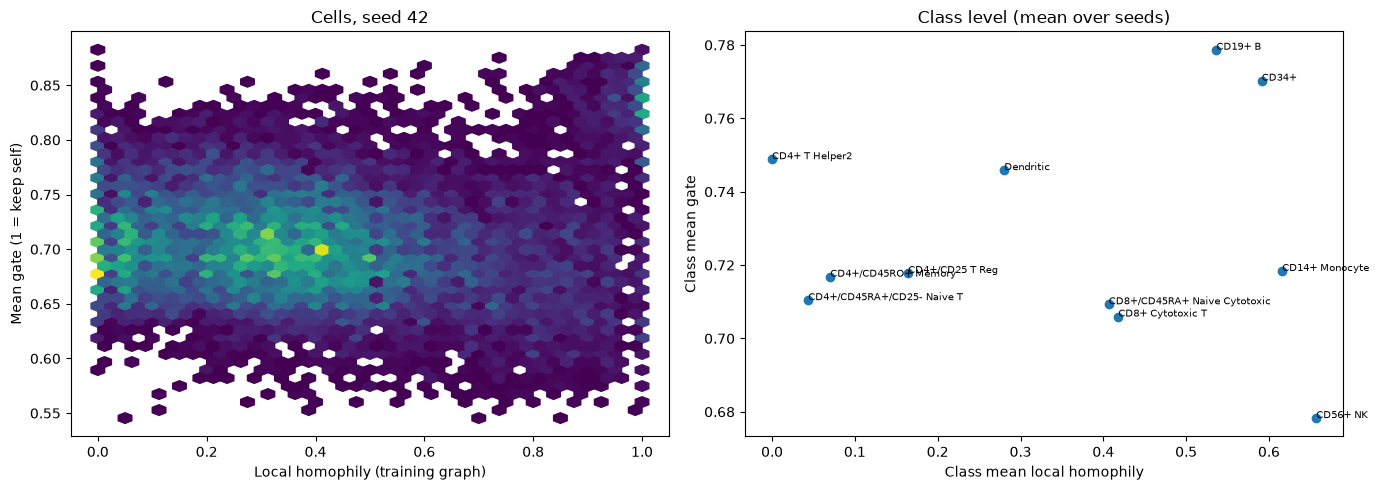

In [13]:
fig = interp.plot_gate_vs_homophily(
    focus_runs["gated_gcn"][SEEDS[0]], local, class_means, SEEDS[0]
)
fig.savefig(OUT / "validation_gate_vs_homophily.png", dpi=150)

## 5. Gradient attribution through PCA loadings

In [14]:
pcs = np.load(EXPORT_ROOT / "X_pca.npy", allow_pickle=False)  # unscaled model input
loadings, gene_names, hvg, expression = interp.load_expression(
    PROCESSED_H5AD, focus_data.cell_ids
)
print(f"Genes: {len(gene_names):,}; HVGs: {hvg.sum():,}; loadings: {loadings.shape}")

# Attributions are only valid if loadings, expression and PCs belong together.
min_corr = interp.check_pca_loadings(expression, loadings, hvg, pcs)
print(f"Min PC correlation: {min_corr:.4f}")
assert min_corr > 0.99, "Loadings do not reproduce the PCs."

Genes: 13,200; HVGs: 2,000; loadings: (13200, 50)
Min PC correlation: 1.0000


In [15]:
# load_data standardises the PCs with a StandardScaler fitted on labelled cells.
scale = pcs[focus_data.train_mask].astype(np.float64).std(axis=0)
eval_mask = focus_data.validation_mask

models = {
    name: [
        interp.load_model(run.spec, focus_data, CHECKPOINT_DIRS)
        for run in runs.values()
    ]
    for name, runs in focus_runs.items()
}
models["untrained_gated_gcn"] = [
    interp.untrained_model("gated_gcn", focus_data, FOCUS_DEPTH)
]
attributions = {
    name: interp.mean_attribution(
        group, focus_data, eval_mask, scale, loadings, gene_names
    )
    for name, group in models.items()
}
recovery = interp.recovery_table(attributions, pd.Series(hvg, index=gene_names))
recovery.to_csv(OUT / "validation_marker_recovery.csv", index=False)

print(
    "Not among the HVGs, so not scored:",
    sorted(set(recovery.loc[~recovery["in_hvg"], "marker"])),
)
display(
    recovery.pivot_table(
        index=["marker", "celltype"], columns="model", values="top_percent"
    ).round(1)
)

Not among the HVGs, so not scored: ['CD3E']


,model,gated_gcn,gcn,graphsage,untrained_gated_gcn
marker,celltype,,,,
LYZ,CD14+ Monocyte,0.4,0.4,0.4,1.4
MS4A1,CD19+ B,1.0,1.2,1.0,1.7
NKG7,CD56+ NK,0.1,0.1,0.1,98.9


## 6. UMAPs

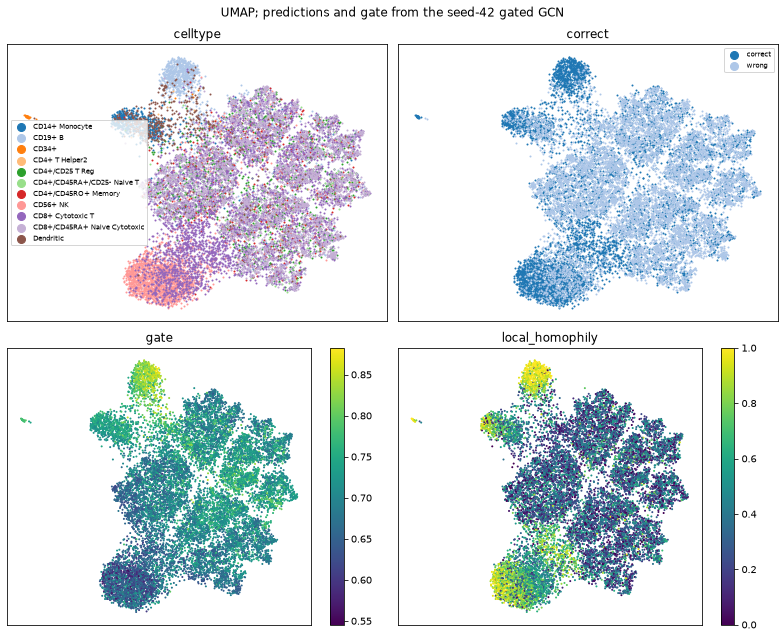

In [16]:
subset, coords = interp.umap_coords(
    labels, pcs, OUT / f"umap_{UMAP_CELLS}.npz", UMAP_CELLS
)
run = focus_runs["gated_gcn"][SEEDS[0]]
predicted = np.asarray(class_names)[run.predictions[subset]]
colourings = {
    "celltype": cell_types[subset],
    "correct": np.where(predicted == cell_types[subset], "correct", "wrong"),
    "gate": run.gate[subset],
    "local_homophily": local[subset],
}
fig = interp.plot_umap(
    coords, colourings, f"UMAP; predictions and gate from the seed-{SEEDS[0]} gated GCN"
)
fig.savefig(OUT / "umap.png", dpi=150)

## 7. Dropout

In [17]:
# If neighbour averaging smooths dropout, gnn_minus_mlp is highest in bin 1.
n_genes = interp.genes_detected(PROCESSED_H5AD, focus_data.cell_ids)
mlp_predictions = np.load(MLP_PREDICTIONS[FOCUS_BUDGET], allow_pickle=False)
dropout = interp.dropout_table(focus_runs, mlp_predictions, n_genes, cell_types)
dropout.to_csv(OUT / "validation_dropout.csv")
display(dropout.round(3))

n_cells  median_genes  mlp_accuracy  accuracy_mean  \
bin model                                                           
1   gated_gcn     3276          87.0         0.406          0.367   
    gcn           3276          87.0         0.406          0.334   
    graphsage     3276          87.0         0.406          0.378   
2   gated_gcn     3281         105.0         0.461          0.425   
    gcn           3281         105.0         0.461          0.400   
    graphsage     3281         105.0         0.461          0.439   
3   gated_gcn     3277         115.0         0.507          0.462   
    gcn           3277         115.0         0.507          0.442   
    graphsage     3277         115.0         0.507          0.479   
4   gated_gcn     3282         128.0         0.546          0.505   
    gcn           3282         128.0         0.546          0.487   
    graphsage     3282         128.0         0.546          0.514   

               gnn_minus_mlp_mean  gnn_minus_mlp_std  
bin model                                             
1   gated_gcn              -0.039              0.011  
    gcn                    -0.071              0.008  
    graphsage              -0.028              0.009  
2   gated_gcn              -0.036              0.006  
    gcn                    -0.061              0.009  
    graphsage              -0.022              0.011  
3   gated_gcn              -0.045              0.004  
    gcn                    -0.065              0.006  
    graphsage              -0.028              0.009  
4   gated_gcn              -0.041              0.006  
    gcn                    -0.059              0.008  
    graphsage              -0.032              0.010